# Book Review Popularity — Dataset Inspection & EDA
**Next step after downloading the preprocessed CSV (about 1.98 million rows).**

This notebook is deliberately staged to avoid loading the entire dataset into RAM immediately. It:
1. Locates or asks you to set the CSV path.
2. Inspects the schema and a small sample.
3. Counts rows and profiles missing values in chunks.
4. Helps identify a possible popularity target without assuming column names.
5. Runs lightweight EDA and saves a compact inspection report.

**Important:** Review the detected columns and target before training. Do not use likes/comments as input features if they were used to create the popularity label; that can cause target leakage. This notebook does not train models yet.

## 1. Configure the CSV path

If the CSV is in Google Drive, mount Drive and set `CSV_PATH` below. If it is uploaded directly into the Colab session, use `/content/your_file.csv`.

Run the cell and edit the path if needed.

In [3]:
from pathlib import Path
import os, json, math, warnings
warnings.filterwarnings("ignore")

# Uncomment in Google Colab if your file is in Google Drive:
from google.colab import drive
drive.mount('/content/drive')

# EDIT THIS to your actual CSV path:
CSV_PATH = "/content/drive/MyDrive/filtered_reviews .csv"

path = Path(CSV_PATH)
print("Path exists:", path.exists())
if path.exists():
    print(f"File size: {path.stat().st_size / (1024**3):.3f} GB")
else:
    print("Update CSV_PATH to the location of your downloaded CSV before continuing.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Path exists: True
File size: 2.194 GB


## 2. Install/import libraries

In [4]:
%pip -q install pandas numpy matplotlib seaborn

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_colwidth", 160)
sns.set_theme()

## 3. Inspect a small sample first

This reads only 1,000 rows. Check the column names and sample values before choosing a target.

In [6]:
assert path.exists(), f"CSV not found: {CSV_PATH}. Edit CSV_PATH in Section 1."

sample = pd.read_csv(CSV_PATH, nrows=1000, low_memory=False)
print("Sample shape:", sample.shape)
print("\nColumn names:")
print(sample.columns.tolist())
print("\nData types:")
display(sample.dtypes.astype(str).rename("dtype").to_frame())
print("\nFirst 5 rows:")
display(sample.head())
print("\nSample summary:")
display(sample.describe(include="all").T)

Sample shape: (1000, 10)

Column names:
['book_id', 'user_reviews', 'user_rating', 'avg_rating', 'ratings_count', 'review_text', 'days_since_review', 'review_likes', 'like_share', 'popular']

Data types:


,dtype
book_id,int64
user_reviews,int64
user_rating,int64
avg_rating,float64
ratings_count,float64
review_text,object
days_since_review,int64
review_likes,float64
like_share,float64
popular,int64



First 5 rows:


,book_id,user_reviews,user_rating,avg_rating,ratings_count,review_text,days_since_review,review_likes,like_share,popular
0,18245960,218,5,4.01,6336.0,"This is a special book. It started slow for about the first third, then in the middle third it started to get interesting, then the last third blew my mind....",96,29.0,0.145729,1
1,29983426,218,5,3.90,439.0,"I decided to give up eating processed sugar for the month of January, and so reading a book with this title seemed like it would help me adhere. And not onl...",299,32.0,0.492308,1
2,28114110,218,4,4.00,880.0,"Kevin Kelly, who is a Wired co-founder, lays out technological trends that are ""inevitable"". Like too many nonfiction books, I found a few chapters to be wo...",327,14.0,0.191781,1
3,28684704,218,3,4.10,13990.0,"A fun, fast paced science fiction thriller. I read it in 2 nights and couldn't put it down. The book is about the quantum theory of many worlds which states...",353,22.0,0.021782,1
4,28119237,218,4,4.04,10078.0,"A fascinating book about community and belonging, and how modern society has moved us away from our roots in potentially signifiant ways. The book opens wit...",407,32.0,0.113074,1



Sample summary:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
book_id,1000.0,NaN,NaN,NaN,19978302.58,9789592.477154,2.0,17156308.25,22233123.0,26770632.75,36252773.0
user_reviews,1000.0,NaN,NaN,NaN,599.336,334.373481,1.0,218.0,833.0,833.0,833.0
user_rating,1000.0,NaN,NaN,NaN,4.238,0.910046,0.0,4.0,4.0,5.0,5.0
avg_rating,1000.0,NaN,NaN,NaN,4.05704,0.26132,2.84,3.91,4.09,4.23,4.91
ratings_count,1000.0,NaN,NaN,NaN,67881.99,303423.153387,85.0,1835.0,6158.0,19820.0,4899965.0
review_text,1000,1000,The take away for me was more about the challenge to the claim of a medical cure for imbalanced brain chemicals than the epidemic part. According to Whitake...,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
days_since_review,1000.0,NaN,NaN,NaN,1223.967,916.932375,15.0,566.0,1072.5,1553.75,4094.0
review_likes,1000.0,NaN,NaN,NaN,9.618,12.775496,1.0,2.0,6.0,13.0,167.0
like_share,1000.0,NaN,NaN,NaN,0.030387,0.075339,0.000043,0.004068,0.010535,0.025478,0.863158
popular,1000.0,NaN,NaN,NaN,0.307,0.46148,0.0,0.0,0.0,1.0,1.0


## 4. Search for likely target and feature columns

The paper frames popularity as a **binary classification** target, but your CSV's column names may differ. This cell only suggests candidates; it does not select a target automatically.

In [7]:
keywords = ["popular", "target", "label", "class", "like", "comment", "helpful",
            "vote", "share", "review", "rating", "date", "user", "book"]
candidate_rows = []
for col in sample.columns:
    name = str(col)
    hits = [k for k in keywords if k in name.lower()]
    if hits:
        candidate_rows.append({"column": name, "dtype": str(sample[col].dtype),
                               "sample_non_null": int(sample[col].notna().sum()),
                               "keyword_matches": ", ".join(hits),
                               "sample_values": sample[col].dropna().astype(str).head(3).tolist()})
candidates = pd.DataFrame(candidate_rows)
display(candidates if len(candidates) else pd.DataFrame({"message": ["No likely columns found; inspect all column names manually."]}))

,column,dtype,sample_non_null,keyword_matches,sample_values
0,book_id,int64,1000,book,"[18245960, 29983426, 28114110]"
1,user_reviews,int64,1000,"review, user","[218, 218, 218]"
2,user_rating,int64,1000,"rating, user","[5, 5, 4]"
3,avg_rating,float64,1000,rating,"[4.01, 3.9, 4.0]"
4,ratings_count,float64,1000,rating,"[6336.0, 439.0, 880.0]"
5,review_text,object,1000,review,"[This is a special book. It started slow for about the first third, then in the middle third it started to get interesting, then the last third blew my mind..."
6,days_since_review,int64,1000,review,"[96, 299, 327]"
7,review_likes,float64,1000,"like, review","[29.0, 32.0, 14.0]"
8,like_share,float64,1000,"like, share","[0.1457286432160804, 0.4923076923076923, 0.1917808219178082]"
9,popular,int64,1000,popular,"[1, 1, 1]"


## 5. Count rows and estimate memory safely

Chunked reading avoids retaining all 1.98 million rows in memory. This pass may take a few minutes depending on file size.

In [8]:
CHUNK_SIZE = 100_000
total_rows = 0
chunk_count = 0
for chunk in pd.read_csv(CSV_PATH, chunksize=CHUNK_SIZE, low_memory=False):
    total_rows += len(chunk)
    chunk_count += 1
print(f"Total rows: {total_rows:,}")
print(f"Chunks processed: {chunk_count}")

Total rows: 1,981,129
Chunks processed: 20


## 6. Missing values and data types across the full CSV

This streams through the dataset and aggregates missing values. It does not store all rows in memory.

In [9]:
missing_counts = None
dtype_map = None
for chunk in pd.read_csv(CSV_PATH, chunksize=CHUNK_SIZE, low_memory=False):
    counts = chunk.isna().sum()
    missing_counts = counts if missing_counts is None else missing_counts.add(counts, fill_value=0)
    if dtype_map is None:
        dtype_map = chunk.dtypes.astype(str)

missing_report = pd.DataFrame({
    "missing_count": missing_counts.astype("int64"),
    "missing_percent": (missing_counts / total_rows * 100).round(3),
    "dtype_first_chunk": dtype_map
}).sort_values("missing_percent", ascending=False)
display(missing_report)
missing_report.to_csv("missing_values_report.csv")
print("Saved: missing_values_report.csv")

,missing_count,missing_percent,dtype_first_chunk
book_id,0,0.0,int64
user_reviews,0,0.0,int64
user_rating,0,0.0,int64
avg_rating,0,0.0,float64
ratings_count,0,0.0,float64
review_text,0,0.0,object
days_since_review,0,0.0,int64
review_likes,0,0.0,float64
like_share,0,0.0,float64
popular,0,0.0,int64


Saved: missing_values_report.csv


## 7. Inspect possible target distributions

After checking Section 4, enter the exact column name of your existing popularity label. Leave `TARGET_COL = None` if no label exists or you are unsure.

For a binary label, check whether values are 0/1 or equivalent. If the label is absent, don't invent one from unrelated columns; inspect the dataset documentation and the paper's label definition first.

In [10]:
# EDIT only after reviewing the columns above, e.g. TARGET_COL = "popular"
TARGET_COL = None

if TARGET_COL is None:
    print("TARGET_COL is None. Set it to the verified popularity-label column to inspect its distribution.")
else:
    if TARGET_COL not in sample.columns:
        print(f"{TARGET_COL!r} is not in the sample columns. Check spelling.")
    else:
        print("Sample target values:")
        display(sample[TARGET_COL].value_counts(dropna=False).head(30).to_frame("count"))
        print("\nSample target proportions:")
        display(sample[TARGET_COL].value_counts(normalize=True, dropna=False).mul(100).round(2).to_frame("percent"))

TARGET_COL is None. Set it to the verified popularity-label column to inspect its distribution.


## 8. Lightweight full-dataset target counts (optional)

Set `TARGET_COL` above, then run this cell to count the target values across the full dataset without loading the entire CSV. This is useful for measuring class imbalance.

In [11]:
if TARGET_COL is None:
    print("Set TARGET_COL in Section 7 first.")
else:
    if TARGET_COL not in sample.columns:
        print(f"Target column {TARGET_COL!r} not found.")
    else:
        counts = {}
        for chunk in pd.read_csv(CSV_PATH, usecols=[TARGET_COL], chunksize=CHUNK_SIZE, low_memory=False):
            vc = chunk[TARGET_COL].value_counts(dropna=False)
            for value, count in vc.items():
                key = str(value)
                counts[key] = counts.get(key, 0) + int(count)
        target_counts = pd.Series(counts, name="count").sort_values(ascending=False).to_frame()
        target_counts["percent"] = (target_counts["count"] / total_rows * 100).round(3)
        display(target_counts)
        target_counts.to_csv("target_distribution.csv")
        print("Saved: target_distribution.csv")

Set TARGET_COL in Section 7 first.


## 9. Numeric summaries and simple plots from a sample

These plots are for initial exploration only. For large files, we use a sample rather than reading every row into memory.

Numeric columns: ['book_id', 'user_reviews', 'user_rating', 'avg_rating', 'ratings_count', 'days_since_review', 'review_likes', 'like_share', 'popular']


,count,mean,std,min,25%,50%,75%,max
book_id,50000.0,1.511449e+07,9.963862e+06,1.00000,6.811268e+06,1.615129e+07,2.289145e+07,36328685.00
user_reviews,50000.0,3.206336e+02,4.409498e+02,1.00000,4.100000e+01,1.400000e+02,3.750000e+02,1830.00
user_rating,50000.0,3.909240e+00,1.241078e+00,0.00000,3.000000e+00,4.000000e+00,5.000000e+00,5.00
avg_rating,50000.0,3.998622e+00,2.780395e-01,1.28000,3.830000e+00,4.020000e+00,4.190000e+00,4.91
ratings_count,50000.0,1.053539e+05,3.730233e+05,2.00000,2.121000e+03,9.231000e+03,4.826600e+04,4899965.00
days_since_review,50000.0,1.332092e+03,8.248196e+02,10.00000,6.920000e+02,1.264000e+03,1.776000e+03,4094.00
review_likes,50000.0,6.880740e+00,2.057665e+01,1.00000,1.000000e+00,2.000000e+00,5.000000e+00,1514.00
like_share,50000.0,2.679326e-02,7.897083e-02,0.00003,1.412429e-03,5.763689e-03,1.724138e-02,1.00
popular,50000.0,2.293600e-01,4.204254e-01,0.00000,0.000000e+00,0.000000e+00,0.000000e+00,1.00


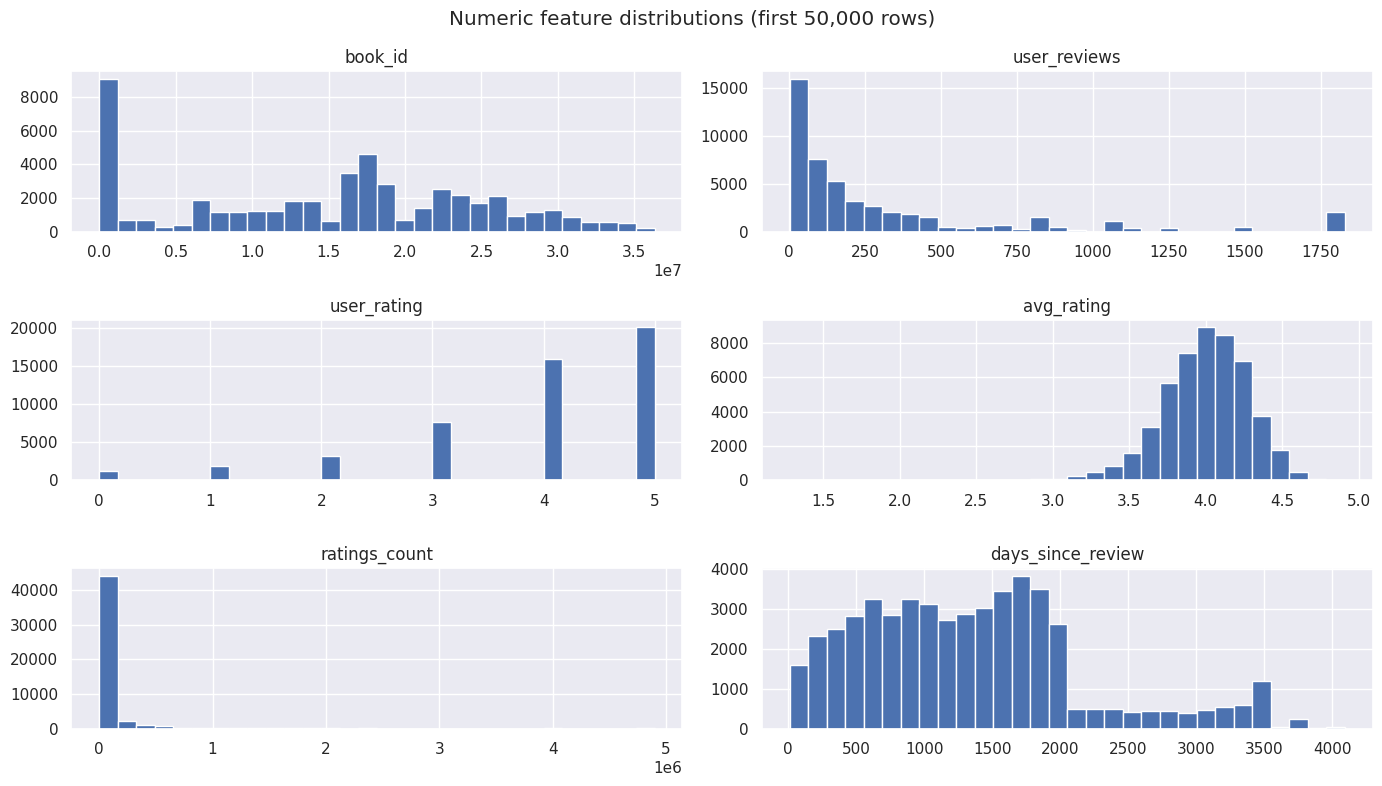

In [12]:
# Random sample for plotting; adjust nrows if your CSV is very large.
plot_sample = pd.read_csv(CSV_PATH, nrows=50_000, low_memory=False)
numeric_cols = plot_sample.select_dtypes(include=np.number).columns.tolist()
print("Numeric columns:", numeric_cols)

if numeric_cols:
    display(plot_sample[numeric_cols].describe().T)
    plot_sample[numeric_cols[:6]].hist(bins=30, figsize=(14, 8))
    plt.suptitle("Numeric feature distributions (first 50,000 rows)")
    plt.tight_layout()
    plt.show()
else:
    print("No numeric columns detected in this sample.")

## 10. Check review-text column and review lengths (optional)

Set `TEXT_COL` to the exact review-text column name. This only processes up to 50,000 sampled rows.

In [13]:
# EDIT after reviewing the column names, e.g. TEXT_COL = "review_text"
TEXT_COL = None

if TEXT_COL is None:
    print("Set TEXT_COL to the verified review-text column.")
elif TEXT_COL not in plot_sample.columns:
    print(f"{TEXT_COL!r} not found in the 50,000-row sample.")
else:
    text_series = plot_sample[TEXT_COL].dropna().astype(str)
    lengths = text_series.str.split().str.len()
    print("Non-null reviews in sample:", len(text_series))
    display(lengths.describe().to_frame("word_count"))
    lengths.clip(upper=lengths.quantile(0.99)).hist(bins=40, figsize=(9, 4))
    plt.title("Review word-count distribution (capped at 99th percentile)")
    plt.xlabel("Word count")
    plt.ylabel("Frequency")
    plt.show()

Set TEXT_COL to the verified review-text column.


## 11. Save a compact inspection report

This report captures row count, columns, types, missing values, and your chosen target/text columns. It can be shared to plan the training notebook.

In [14]:
report = {
    "csv_path": CSV_PATH,
    "file_size_gb": round(path.stat().st_size / (1024**3), 3),
    "total_rows": int(total_rows),
    "number_of_columns": int(len(sample.columns)),
    "columns": sample.columns.tolist(),
    "dtypes_sample": sample.dtypes.astype(str).to_dict(),
    "target_column_candidate_selected": TARGET_COL,
    "text_column_selected": TEXT_COL
}
with open("dataset_inspection_report.json", "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2, ensure_ascii=False)
print("Saved: dataset_inspection_report.json")
print(json.dumps(report, indent=2, ensure_ascii=False))

Saved: dataset_inspection_report.json
{
  "csv_path": "/content/drive/MyDrive/filtered_reviews .csv",
  "file_size_gb": 2.194,
  "total_rows": 1981129,
  "number_of_columns": 10,
  "columns": [
    "book_id",
    "user_reviews",
    "user_rating",
    "avg_rating",
    "ratings_count",
    "review_text",
    "days_since_review",
    "review_likes",
    "like_share",
    "popular"
  ],
  "dtypes_sample": {
    "book_id": "int64",
    "user_reviews": "int64",
    "user_rating": "int64",
    "avg_rating": "float64",
    "ratings_count": "float64",
    "review_text": "object",
    "days_since_review": "int64",
    "review_likes": "float64",
    "like_share": "float64",
    "popular": "int64"
  },
  "target_column_candidate_selected": null,
  "text_column_selected": null
}


## 12. What to do after this notebook

1. Confirm the actual popularity target and its definition.
2. Confirm the review-text column and relevant numeric features.
3. Check the target distribution for class imbalance.
4. Split train/test **before fitting TF-IDF** to avoid data leakage.
5. Build a training notebook for Logistic Regression + TF-IDF first, then compare XGBoost or a neural network if compute permits.
6. Keep any features derived from the target (such as likes/comments used to compute popularity) out of model inputs.

**Expected outputs:** `missing_values_report.csv`, `target_distribution.csv` (if target selected), and `dataset_inspection_report.json`.